# 螞蟻滅火機器人
## 進度條0---100%
### 1.建立動態火場物理模型與產出三色灰階網格地圖
### 2.開發逃生人員的避難路線規劃演算法及寫出對照組演算法
### 3.撰寫滅火機器人的優先標的選擇、無衝突避讓與地圖動態更新
### 4.執行多案例模擬並繪製專題圖表
**13 張標準模擬圖表自動化繪製：
寫出 Plot 圖表腳本，自動產出各案例之「泊松熱圖」、「灰階合併圖」、「第一次/第二次 AACO 路線對比圖」、「AACO/ACO/Dijkstra 路線比較圖」、「迭代收斂折線圖」及「機器人移動軌跡圖」

### 一、核心研究在於建構動態火場物理模型（火源點與煙霧擴散），並結合三色灰階網格地圖與適應性蟻群演算法（AACO）

#### 火源點物理模型
依據泊松分佈機率質量函數生成火源點與隨機燃燒強度，並會自動判斷火源是否生成在牆壁/障礙物上（若落在障礙物上則自動捨棄）。

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math

def generate_poisson_fire_sources(grid_map, lambda_param=4.0, num_candidates=5, fire_intensity_scale=10.0):
    """
    依據泊松分佈產生隨機火源點與強度 (專題論文公式 3.11)
    
    參數:
    - grid_map: 2D numpy array, 靜態建築模型網格 (0 代表障礙物/牆壁, 255 代表可通行區域)
    - lambda_param: 泊松分佈參數 λ (平均發生強度/次數)
    - num_candidates: 隨機嘗試生成的火源候選數量
    - fire_intensity_scale: 火源強度的放大係數
    
    返回:
    - fire_matrix: 2D numpy array, 火源強度矩陣 (M_xy)
    - fire_sources: list of tuple, 成功生成在可通行區域的火源座標 [(x1, y1), (x2, y2)...]
    """
    rows, cols = grid_map.shape
    fire_matrix = np.zeros((rows, cols), dtype=np.float32)
    fire_sources = []
    
    # 泊松分佈機率質量函數 PMF: P(X = k) = (e^(-λ) * λ^k) / k!
    def poisson_pmf(k, lam):
        return (math.exp(-lam) * (lam ** k)) / math.factorial(k)
    
    # 隨機挑選位置並依據泊松機率賦予強度
    for _ in range(num_candidates):
        rx = np.random.randint(0, cols)
        ry = np.random.randint(0, rows)
        
        # 步驟 7 & 8: 判斷是否生成在可燃燒/可移動區域 (grid_map != 0)
        if grid_map[ry, rx] > 0:
            # 隨機生成事件次數 k (0 ~ 15)
            k = np.random.poisson(lam=lambda_param)
            pmf_val = poisson_pmf(k, lambda_param)
            
            # 計算火源強度 M_xy
            intensity = pmf_val * fire_intensity_scale * 100.0
            
            if intensity > 0:
                fire_matrix[ry, rx] += intensity
                fire_sources.append((rx, ry))
                
    return fire_matrix, fire_sources
def simulate_smoke_diffusion(grid_map, fire_sources, steps=50, D=0.25, dt=1.0, S=2.0):
    """
    流體力學煙霧擴散模擬 (專題論文公式 3.12 與 3.13)
    
    參數:
    - grid_map: 2D numpy array, 靜態建築地圖 (0 代表牆壁，煙霧無法穿越)
    - fire_sources: list of tuple, 火源點座標列表 [(xf1, yf1), (xf2, yf2)...]
    - steps: 擴散時間步長/迭代次數
    - D: 擴散係數 (Diffusion Coefficient)
    - dt: 時間步長 Δt
    - S: 火源釋放濃度增加量 (論文預設以 2 表示)
    
    返回:
    - concentration_map: 2D numpy array, 最終各節點之煙霧濃度矩陣 C(x,y)
    """
    rows, cols = grid_map.shape
    c_current = np.zeros((rows, cols), dtype=np.float32)
    
    for t in range(steps):
        c_next = np.copy(c_current)
        
        # 1. 遍歷網格進行流體力學四方向擴散計算 (公式 3.12)
        for y in range(1, rows - 1):
            for x in range(1, cols - 1):
                # 牆壁/障礙物節點不積聚與擴散煙霧
                if grid_map[y, x] == 0:
                    continue
                
                # 取出上下左右相鄰節點濃度 (若相鄰點為牆壁則視為無法擴散，取當前濃度)
                c_up    = c_current[y-1, x] if grid_map[y-1, x] > 0 else c_current[y, x]
                c_down  = c_current[y+1, x] if grid_map[y+1, x] > 0 else c_current[y, x]
                c_left  = c_current[y, x-1] if grid_map[y, x-1] > 0 else c_current[y, x]
                c_right = c_current[y, x+1] if grid_map[y, x+1] > 0 else c_current[y, x]
                
                neighbor_avg = (c_up + c_down + c_left + c_right) / 4.0
                
                # 濃度更新公式 (3.12)
                c_next[y, x] = c_current[y, x] + D * dt * (neighbor_avg - c_current[y, x])
        
        # 2. 火源位置持續釋放煙霧 (公式 3.13: c_new(xf, yf) = c_new(xf, yf) + S)
        for (xf, yf) in fire_sources:
            if grid_map[yf, xf] > 0:
                c_next[yf, xf] += S
                
        c_current = np.copy(c_next)
        
    return c_current    
    
# ==========================================
# 測試 1：泊松火源生成獨立運作示範
# ==========================================
if __name__ == "__main__":
    # 建立 100x100 的空地圖 (四周為牆壁 0，中間可通行 255)
    test_grid = np.full((100, 100), 255, dtype=np.uint8)
    test_grid[0, :] = test_grid[-1, :] = test_grid[:, 0] = test_grid[:, -1] = 0 # 邊界牆體
    
    # 生成泊松火源
    fire_m, sources = generate_poisson_fire_sources(test_grid, lambda_param=4.0, num_candidates=8)
    
    print(f"成功生成之可燃燒區火源點座標數量: {len(sources)}")
    for idx, (fx, fy) in enumerate(sources):
        print(f" 火源 {idx+1}: 座標 (x={fx}, y={fy}), 火源強度 = {fire_m[fy, fx]:.3f}")


成功生成之可燃燒區火源點座標數量: 8
 火源 1: 座標 (x=35, y=64), 火源強度 = 195.367
 火源 2: 座標 (x=49, y=1), 火源強度 = 146.525
 火源 3: 座標 (x=93, y=24), 火源強度 = 156.293
 火源 4: 座標 (x=54, y=46), 火源強度 = 59.540
 火源 5: 座標 (x=40, y=2), 火源強度 = 104.196
 火源 6: 座標 (x=49, y=64), 火源強度 = 73.263
 火源 7: 座標 (x=73, y=77), 火源強度 = 156.293
 火源 8: 座標 (x=11, y=12), 火源強度 = 195.367


#### 煙霧擴散物理模型
論文第三章的氣體擴散與濃度更新公式 (3.12) 以及 火源持續釋放濃度公式 (3.13)，模擬煙霧隨時間步長向四周網格擴散並逐漸積聚濃度的物理過程。

In [3]:
import numpy as np

def simulate_smoke_diffusion(grid_map, fire_sources, steps=50, D=0.25, dt=1.0, S=2.0):
    """
    流體力學煙霧擴散模擬 (專題論文公式 3.12 與 3.13)
    
    參數:
    - grid_map: 2D numpy array, 靜態建築地圖 (0 代表牆壁，煙霧無法穿越)
    - fire_sources: list of tuple, 火源點座標列表 [(xf1, yf1), (xf2, yf2)...]
    - steps: 擴散時間步長/迭代次數
    - D: 擴散係數 (Diffusion Coefficient)
    - dt: 時間步長 Δt
    - S: 火源釋放濃度增加量 (論文預設以 2 表示)
    
    返回:
    - concentration_map: 2D numpy array, 最終各節點之煙霧濃度矩陣 C(x,y)
    """
    rows, cols = grid_map.shape
    c_current = np.zeros((rows, cols), dtype=np.float32)
    
    for t in range(steps):
        c_next = np.copy(c_current)
        
        # 1. 遍歷網格進行流體力學四方向擴散計算 (公式 3.12)
        for y in range(1, rows - 1):
            for x in range(1, cols - 1):
                # 牆壁/障礙物節點不積聚與擴散煙霧
                if grid_map[y, x] == 0:
                    continue
                
                # 取出上下左右相鄰節點濃度 (若相鄰點為牆壁則視為無法擴散，取當前濃度)
                c_up    = c_current[y-1, x] if grid_map[y-1, x] > 0 else c_current[y, x]
                c_down  = c_current[y+1, x] if grid_map[y+1, x] > 0 else c_current[y, x]
                c_left  = c_current[y, x-1] if grid_map[y, x-1] > 0 else c_current[y, x]
                c_right = c_current[y, x+1] if grid_map[y, x+1] > 0 else c_current[y, x]
                
                neighbor_avg = (c_up + c_down + c_left + c_right) / 4.0
                
                # 濃度更新公式 (3.12)
                c_next[y, x] = c_current[y, x] + D * dt * (neighbor_avg - c_current[y, x])
        
        # 2. 火源位置持續釋放煙霧 (公式 3.13: c_new(xf, yf) = c_new(xf, yf) + S)
        for (xf, yf) in fire_sources:
            if grid_map[yf, xf] > 0:
                c_next[yf, xf] += S
                
        c_current = np.copy(c_next)
        
    return c_current

### 整合

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import math

def generate_poisson_fire_sources(grid_map, lambda_param=4.0, num_candidates=5, fire_intensity_scale=10.0):
    """
    依據泊松分佈產生隨機火源點與強度 (專題論文公式 3.11)
    """
    rows, cols = grid_map.shape
    fire_matrix = np.zeros((rows, cols), dtype=np.float32)
    fire_sources = []
    
    for _ in range(num_candidates):
        rx = np.random.randint(0, cols)
        ry = np.random.randint(0, rows)
        
        # 步驟 7 & 8: 判斷是否生成在可燃燒/可移動區域 (grid_map != 0)
        if grid_map[ry, rx] > 0:
            # 直接從泊松分佈生成火源強度事件數 k (k >= 0)
            k = np.random.poisson(lam=lambda_param)
            
            # 計算火源強度 M_xy (當 k > 0 時才視為有效火源)
            if k > 0:
                intensity = k * fire_intensity_scale
                fire_matrix[ry, rx] += intensity
                fire_sources.append((rx, ry))
                
    return fire_matrix, fire_sources

def simulate_smoke_diffusion(grid_map, fire_sources, steps=50, D=0.25, dt=1.0, S=2.0):
    """
    流體力學煙霧擴散模擬 (專題論文公式 3.12 與 3.13)
    """
    rows, cols = grid_map.shape
    c_current = np.zeros((rows, cols), dtype=np.float32)
    
    for t in range(steps):
        c_next = np.copy(c_current)
        
        # 1. 遍歷網格進行流體力學四方向擴散計算 (公式 3.12)
        for y in range(1, rows - 1):
            for x in range(1, cols - 1):
                # 牆壁/障礙物節點不積聚與擴散煙霧
                if grid_map[y, x] == 0:
                    continue
                
                # 取出上下左右相鄰節點濃度 (牆壁節點不傳遞濃度)
                c_up    = c_current[y-1, x] if grid_map[y-1, x] > 0 else c_current[y, x]
                c_down  = c_current[y+1, x] if grid_map[y+1, x] > 0 else c_current[y, x]
                c_left  = c_current[y, x-1] if grid_map[y, x-1] > 0 else c_current[y, x]
                c_right = c_current[y, x+1] if grid_map[y, x+1] > 0 else c_current[y, x]
                
                neighbor_avg = (c_up + c_down + c_left + c_right) / 4.0
                
                # 濃度更新公式 (3.12)
                c_next[y, x] = c_current[y, x] + D * dt * (neighbor_avg - c_current[y, x])
        
        # 2. 火源位置持續釋放煙霧 (公式 3.13: c_new(xf, yf) = c_new(xf, yf) + S)
        for (xf, yf) in fire_sources:
            if grid_map[yf, xf] > 0:
                c_next[yf, xf] += S
                
        c_current = np.copy(c_next)
        
    return c_current

# ==========================================
# 測試執行
# ==========================================
if __name__ == "__main__":
    test_grid = np.full((100, 100), 255, dtype=np.uint8)
    test_grid[0, :] = test_grid[-1, :] = test_grid[:, 0] = test_grid[:, -1] = 0 # 邊界牆體
    
    fire_m, sources = generate_poisson_fire_sources(test_grid, lambda_param=4.0, num_candidates=8)
    smoke_m = simulate_smoke_diffusion(test_grid, sources, steps=30)
    
    print(f"成功生成之可燃燒區火源點數量: {len(sources)}")
    print(f"煙霧擴散最高濃度: {np.max(smoke_m):.2f}")

成功生成之可燃燒區火源點數量: 8
煙霧擴散最高濃度: 11.76


### 純網格模擬

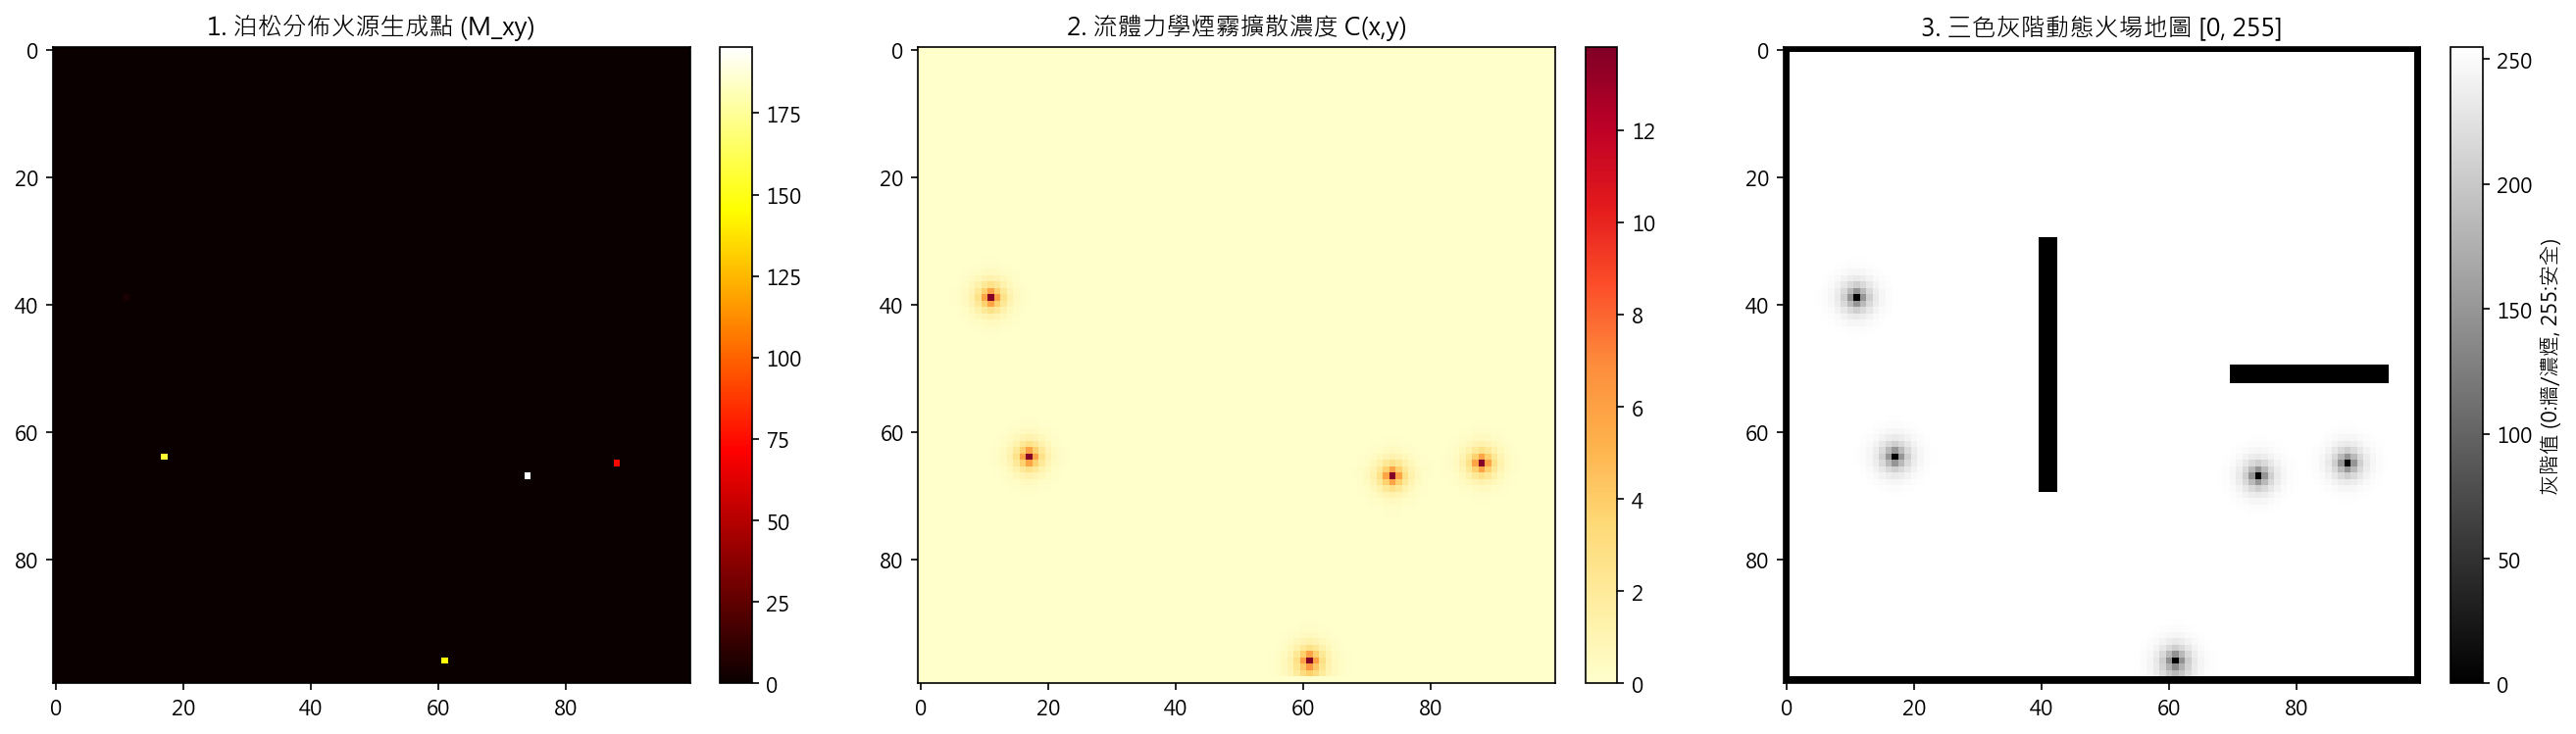

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# 解決中文顯示問題
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'SimHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

def normalize_and_invert_gray_map(smoke_matrix):
    """
    灰階標準化與反轉 (專題論文公式 3.14 與 3.15)
    
    公式 3.14: M_xy = 255 * (M_xy - min(M)) / (max(M) - min(M))
    公式 3.15: New_M = 256 - M
    """
    min_val = np.min(smoke_matrix)
    max_val = np.max(smoke_matrix)
    
    if max_val - min_val == 0:
        M_norm = np.zeros_like(smoke_matrix)
    else:
        # 公式 3.14 標準化至 [0, 255]
        M_norm = 255.0 * (smoke_matrix - min_val) / (max_val - min_val)
        
    # 公式 3.15 反轉：高危害/濃煙變為低灰階值 (接近 0 黑色)，安全區為高灰階值 (接近 255 白色)
    New_M = 256.0 - M_norm
    New_M = np.clip(New_M, 0, 255) # 限制範圍於 [0, 255]
    return New_M.astype(np.uint8)

# ==========================================
# 完整模型測試與成果繪製
# ==========================================
if __name__ == "__main__":
    # 1. 建立 100x100 模擬工廠環境 (含牆壁與障礙物)
    factory_map = np.full((100, 100), 255, dtype=np.uint8)
    factory_map[0, :] = factory_map[-1, :] = factory_map[:, 0] = factory_map[:, -1] = 0 # 外牆
    factory_map[30:70, 40:43] = 0  # 中間隔牆障礙物
    factory_map[50:53, 70:95] = 0  # 右側機房牆體
    
    # 2. 執行泊松火源模型生成火源
    fire_matrix, fire_pts = generate_poisson_fire_sources(
        factory_map, lambda_param=4.0, num_candidates=6, fire_intensity_scale=10.0
    )
    
    # 3. 執行流體力學煙霧擴散模型 (模擬 60 個時間步長)
    smoke_matrix = simulate_smoke_diffusion(
        factory_map, fire_pts, steps=60, D=0.25, dt=1.0, S=2.0
    )
    
    # 4. 進行灰階標準化與反轉 (轉換為 0~255 三色灰階地圖)
    hazard_gray_map = normalize_and_invert_gray_map(smoke_matrix)
    
    # 合併靜態牆壁 (牆壁 0 強制覆蓋)
    final_three_color_map = np.minimum(factory_map, hazard_gray_map)
    
    # 5. 繪製並呈現結果
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=150)
    
    # 圖 1：泊松分佈生成的火源強度熱圖
    im0 = axes[0].imshow(fire_matrix, cmap='hot')
    axes[0].set_title("1. 泊松分佈火源生成點 (M_xy)", fontsize=12)
    fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)
    
    # 圖 2：流體力學煙霧擴散濃度圖
    im1 = axes[1].imshow(smoke_matrix, cmap='YlOrRd')
    axes[1].set_title("2. 流體力學煙霧擴散濃度 C(x,y)", fontsize=12)
    fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)
    
    # 圖 3：最終三色灰階網格地圖 (AACO 演算法輸入矩陣)
    im2 = axes[2].imshow(final_three_color_map, cmap='gray', vmin=0, vmax=255)
    axes[2].set_title("3. 三色灰階動態火場地圖 [0, 255]", fontsize=12)
    fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04, label="灰階值 (0:牆/濃煙, 255:安全)")
    
    plt.tight_layout()
    plt.show()

## 方案：Matplotlib 互動式畫筆點擊編輯器（最方便、Python 原生）
在 Jupyter Notebook 或 Python GUI 中，直接利用 matplotlib 的滑鼠事件（button_press_event 或 motion_notify_event），讓您可以 用滑鼠點擊或拖曳 網格：滑鼠左鍵：點擊/塗抹網格，將該區塊劃記為 牆壁 (灰階值 0)。   滑鼠右鍵：清除點擊的網格，還原為 可通行區域 (灰階值 255)。   隨時匯出/更新：修改完畢後按下鍵盤按鍵（例如按 s），自動存成最新的 numpy 矩陣 .npy 或 .png 檔，供 AACO 演算法即時帶入重規劃。   

In [4]:
pip install PyQt5

Note: you may need to restart the kernel to use updated packages.


'DOSKEY' ���O�����Υ~���R�O�B�i���檺�{���Χ妸�ɡC


In [5]:
%matplotlib qt
import fitz  # PyMuPDF 套件
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 0. 字型與顯示設定 (避免中文顯示警告)
# ==========================================
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'SimHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

# ==========================================
# 1. 讀取 PDF 並以 300 DPI 渲染 (確保原圖極度清晰)
# ==========================================
pdf_path = "factory.jpg"
grid_rows, grid_cols = 100, 100  # 設定 100x100 網格 (可根據需求修改)

try:
    doc = fitz.open(pdf_path)
    page = doc[0]
    zoom = 300 / 72  # 300 DPI 高畫質放大
    mat = fitz.Matrix(zoom, zoom)
    pix = page.get_pixmap(matrix=mat)

    # 轉換為 RGB 與灰階影像
    high_res_rgb = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
    if pix.n == 4:
        high_res_rgb = cv2.cvtColor(high_res_rgb, cv2.COLOR_RGBA2RGB)
    gray = cv2.cvtColor(high_res_rgb, cv2.COLOR_RGB2GRAY)
    h, w, _ = high_res_rgb.shape

    # 自動提取原始 CAD 牆體作為初始二值化網格 (0為牆/不可走，255為路/可走)
    _, binary_map = cv2.threshold(gray, 200, 255, cv2.THRESH_BINARY)
    kernel = np.ones((3, 3), np.uint8)
    dilated_map = cv2.erode(binary_map, kernel, iterations=1)
    wall_matrix = cv2.resize(dilated_map, (grid_cols, grid_rows), interpolation=cv2.INTER_AREA)
    print("成功載入 PDF 建築結構！")

except Exception as e:
    print(f"無法載入 PDF ({e})，改為建立 {grid_rows}x{grid_cols} 空白網格地圖。")
    h, w = 800, 800
    high_res_rgb = np.full((h, w, 3), 255, dtype=np.uint8)
    wall_matrix = np.full((grid_rows, grid_cols), 255, dtype=np.uint8)

# 備份最原始提取的網格（用於按 R 鍵重置）
original_wall_matrix = wall_matrix.copy()

# ==========================================
# 2. 繪製高清底圖上的純黑色粗線網格
# ==========================================
base_grid_img = high_res_rgb.copy()
row_step = h / grid_rows
col_step = w / grid_cols

black_color = (0, 0, 0)
# 畫縱向黑線
for i in range(1, grid_cols):
    x = int(i * col_step)
    thick = 4 if i % 10 == 0 else 2  # 每 10 格加粗主輔助線
    cv2.line(base_grid_img, (x, 0), (x, h), black_color, thick)

# 畫橫向黑線
for j in range(1, grid_rows):
    y = int(j * row_step)
    thick = 4 if j % 10 == 0 else 2
    cv2.line(base_grid_img, (0, y), (w, y), black_color, thick)

# ==========================================
# 3. 建立【跳出式網格劃記編輯視窗】
# ==========================================
fig, ax = plt.subplots(figsize=(11, 10), dpi=130)
im = ax.imshow(base_grid_img)

title_text = (
    "【動態網格劃記編輯器】\n"
    "• 滑鼠左鍵拖曳：劃記新增【牆壁 / 關閉的門】 (標示為紅色/改為 0 不可走)\n"
    "• 滑鼠右鍵拖曳：擦除還原【通道 / 開啟的門】 (改為 255 可通行)\n"
    "• 鍵盤按 's' 鍵：手動儲存網格 | 鍵盤按 'r' 鍵：重置圖面\n"
    "• 關閉視窗：自動儲存並更新『不能走與可走』的網格陣列！"
)
ax.set_title(title_text, fontsize=11, color='navy', fontweight='bold')
ax.set_xlabel(f"X 網格座標 (0 ~ {grid_cols-1})")
ax.set_ylabel(f"Y 網格座標 (0 ~ {grid_rows-1})")

drawing = False
brush_size = 1  # 塗刷筆刷半徑 (1 表示 3x3 網格區塊，可微調)

def render_display():
    """即時重新渲染：底圖 + 黑色網格 + 手動新增劃記的紅色遮罩"""
    overlay = base_grid_img.copy()
    
    # 找出手動劃記為 0 (牆/關門) 的網格區塊疊加半透明紅色
    for r in range(grid_rows):
        for c in range(grid_cols):
            if wall_matrix[r, c] == 0 and original_wall_matrix[r, c] != 0:
                y1, y2 = int(r * row_step), int((r + 1) * row_step)
                x1, x2 = int(c * col_step), int((c + 1) * col_step)
                overlay[y1:y2, x1:x2] = (overlay[y1:y2, x1:x2] * 0.3 + np.array([230, 30, 30]) * 0.7).astype(np.uint8)
                
    im.set_data(overlay)
    fig.canvas.draw_idle()

def update_point(x, y, value):
    """將滑鼠點擊位置精確對應至網格矩陣中的 (row, col) 並賦值"""
    col = int(x / col_step)
    row = int(y / row_step)
    
    if 0 <= col < grid_cols and 0 <= row < grid_rows:
        r_min, r_max = max(0, row - brush_size), min(grid_rows, row + brush_size + 1)
        c_min, c_max = max(0, col - brush_size), min(grid_cols, col + brush_size + 1)
        
        wall_matrix[r_min:r_max, c_min:c_max] = value
        render_display()

# 滑鼠與鍵盤事件監聽機制
def on_button_press(event):
    global drawing
    if event.inaxes == ax:
        drawing = True
        val = 0 if event.button == 1 else 255  # 左鍵: 0(不可走牆/門), 右鍵: 255(可走通道)
        update_point(event.xdata, event.ydata, val)

def on_motion(event):
    if drawing and event.inaxes == ax:
        val = 0 if event.button == 1 else 255
        update_point(event.xdata, event.ydata, val)

def on_button_release(event):
    global drawing
    drawing = False

def on_key_press(event):
    global wall_matrix
    if event.key == 'r':  # 按 R 鍵重置回到初始狀態
        wall_matrix[:] = original_wall_matrix.copy()
        render_display()
        print("已重置網格為初始狀態！")
    elif event.key == 's':  # 按 S 鍵手動存檔
        save_updated_grid()

def save_updated_grid():
    """自動儲存最新網格數據 (0=不可走，255=可走)"""
    np.save("updated_walkable_grid.npy", wall_matrix)
    cv2.imwrite("updated_walkable_grid.png", wall_matrix)
    
    unwalkable_count = np.sum(wall_matrix == 0)
    walkable_count = np.sum(wall_matrix == 255)
    
    print("\n" + "="*50)
    print("【網格通行狀態已成功自動儲存並更新！】")
    print(f"• 不可通行網格數 (0)   : {unwalkable_count} 個")
    print(f"• 可自由通行網格數 (255): {walkable_count} 個")
    print("• 已儲存 NumPy 矩陣檔 : 'updated_walkable_grid.npy'")
    print("• 已儲存二值化圖像檔   : 'updated_walkable_grid.png'")
    print("="*50 + "\n")

# 綁定事件監聽
fig.canvas.mpl_connect('button_press_event', on_button_press)
fig.canvas.mpl_connect('motion_notify_event', on_motion)
fig.canvas.mpl_connect('button_release_event', on_button_release)
fig.canvas.mpl_connect('key_press_event', on_key_press)

plt.tight_layout()
plt.show()

# 視窗關閉時自動存檔更新
save_updated_grid()

成功載入 PDF 建築結構！

【網格通行狀態已成功自動儲存並更新！】
• 不可通行網格數 (0)   : 4 個
• 可自由通行網格數 (255): 6593 個
• 已儲存 NumPy 矩陣檔 : 'updated_walkable_grid.npy'
• 已儲存二值化圖像檔   : 'updated_walkable_grid.png'




【網格通行狀態已成功自動儲存並更新！】
• 不可通行網格數 (0)   : 1282 個
• 可自由通行網格數 (255): 7772 個
• 已儲存 NumPy 矩陣檔 : 'updated_walkable_grid.npy'
• 已儲存二值化圖像檔   : 'updated_walkable_grid.png'



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math

def generate_poisson_fire_sources(grid_map, lambda_param=4.0, num_candidates=5, fire_intensity_scale=10.0):
    """
    依據泊松分佈產生隨機火源點與強度 (專題論文公式 3.11)
    """
    rows, cols = grid_map.shape
    fire_matrix = np.zeros((rows, cols), dtype=np.float32)
    fire_sources = []
    
    for _ in range(num_candidates):
        rx = np.random.randint(0, cols)
        ry = np.random.randint(0, rows)
        
        # 步驟 7 & 8: 判斷是否生成在可燃燒/可移動區域 (grid_map != 0)
        if grid_map[ry, rx] > 0:
            # 直接從泊松分佈生成火源強度事件數 k (k >= 0)
            k = np.random.poisson(lam=lambda_param)
            
            # 計算火源強度 M_xy (當 k > 0 時才視為有效火源)
            if k > 0:
                intensity = k * fire_intensity_scale
                fire_matrix[ry, rx] += intensity
                fire_sources.append((rx, ry))
                
    return fire_matrix, fire_sources

def simulate_smoke_diffusion(grid_map, fire_sources, steps=50, D=0.25, dt=1.0, S=2.0):
    """
    流體力學煙霧擴散模擬 (專題論文公式 3.12 與 3.13)
    """
    rows, cols = grid_map.shape
    c_current = np.zeros((rows, cols), dtype=np.float32)
    
    for t in range(steps):
        c_next = np.copy(c_current)
        
        # 1. 遍歷網格進行流體力學四方向擴散計算 (公式 3.12)
        for y in range(1, rows - 1):
            for x in range(1, cols - 1):
                # 牆壁/障礙物節點不積聚與擴散煙霧
                if grid_map[y, x] == 0:
                    continue
                
                # 取出上下左右相鄰節點濃度 (牆壁節點不傳遞濃度)
                c_up    = c_current[y-1, x] if grid_map[y-1, x] > 0 else c_current[y, x]
                c_down  = c_current[y+1, x] if grid_map[y+1, x] > 0 else c_current[y, x]
                c_left  = c_current[y, x-1] if grid_map[y, x-1] > 0 else c_current[y, x]
                c_right = c_current[y, x+1] if grid_map[y, x+1] > 0 else c_current[y, x]
                
                neighbor_avg = (c_up + c_down + c_left + c_right) / 4.0
                
                # 濃度更新公式 (3.12)
                c_next[y, x] = c_current[y, x] + D * dt * (neighbor_avg - c_current[y, x])
        
        # 2. 火源位置持續釋放煙霧 (公式 3.13: c_new(xf, yf) = c_new(xf, yf) + S)
        for (xf, yf) in fire_sources:
            if grid_map[yf, xf] > 0:
                c_next[yf, xf] += S
                
        c_current = np.copy(c_next)
        
    return c_current

# ==========================================
# 測試執行
# ==========================================
if __name__ == "__main__":
    test_grid = np.full((100, 100), 255, dtype=np.uint8)
    test_grid[0, :] = test_grid[-1, :] = test_grid[:, 0] = test_grid[:, -1] = 0 # 邊界牆體
    
    fire_m, sources = generate_poisson_fire_sources(test_grid, lambda_param=4.0, num_candidates=8)
    smoke_m = simulate_smoke_diffusion(test_grid, sources, steps=30)
    
    print(f"成功生成之可燃燒區火源點數量: {len(sources)}")
    print(f"煙霧擴散最高濃度: {np.max(smoke_m):.2f}")

成功生成之可燃燒區火源點數量: 8
煙霧擴散最高濃度: 11.91


In [9]:
import numpy as np


def normalize_and_invert_gray_map(M):
    """論文公式 (3.14) 與 (3.15)：將火源/煙霧矩陣進行標準化與反轉 步驟 1:

    標準化到 [0, 255] 步驟 2: 反轉矩陣 (New_M = 256 - M 或 255 - M)
    使強火/濃煙轉為趨近 0 (黑色/障礙區)，無火/安全區轉為趨近 255 (白色/可通行區)
    """
    min_val = np.min(M)
    max_val = np.max(M)

    # 避免分母為 0 的情況
    if max_val == min_val:
        M_norm = np.zeros_like(M)
    else:
        # 公式 (3.14): 標準化
        M_norm = 255.0 * (M - min_val) / (max_val - min_val)

    # 公式 (3.15): 反轉矩陣
    hazard_gray_map = 255.0 - M_norm

    return hazard_gray_map.astype(np.uint8)

In [10]:
import numpy as np
# 直接載入你剛才編輯並儲存的網格矩陣
grid_map = np.load("updated_walkable_grid.npy")

[(90, 65), (40, 53), (25, 11), (11, 98), (28, 92)]


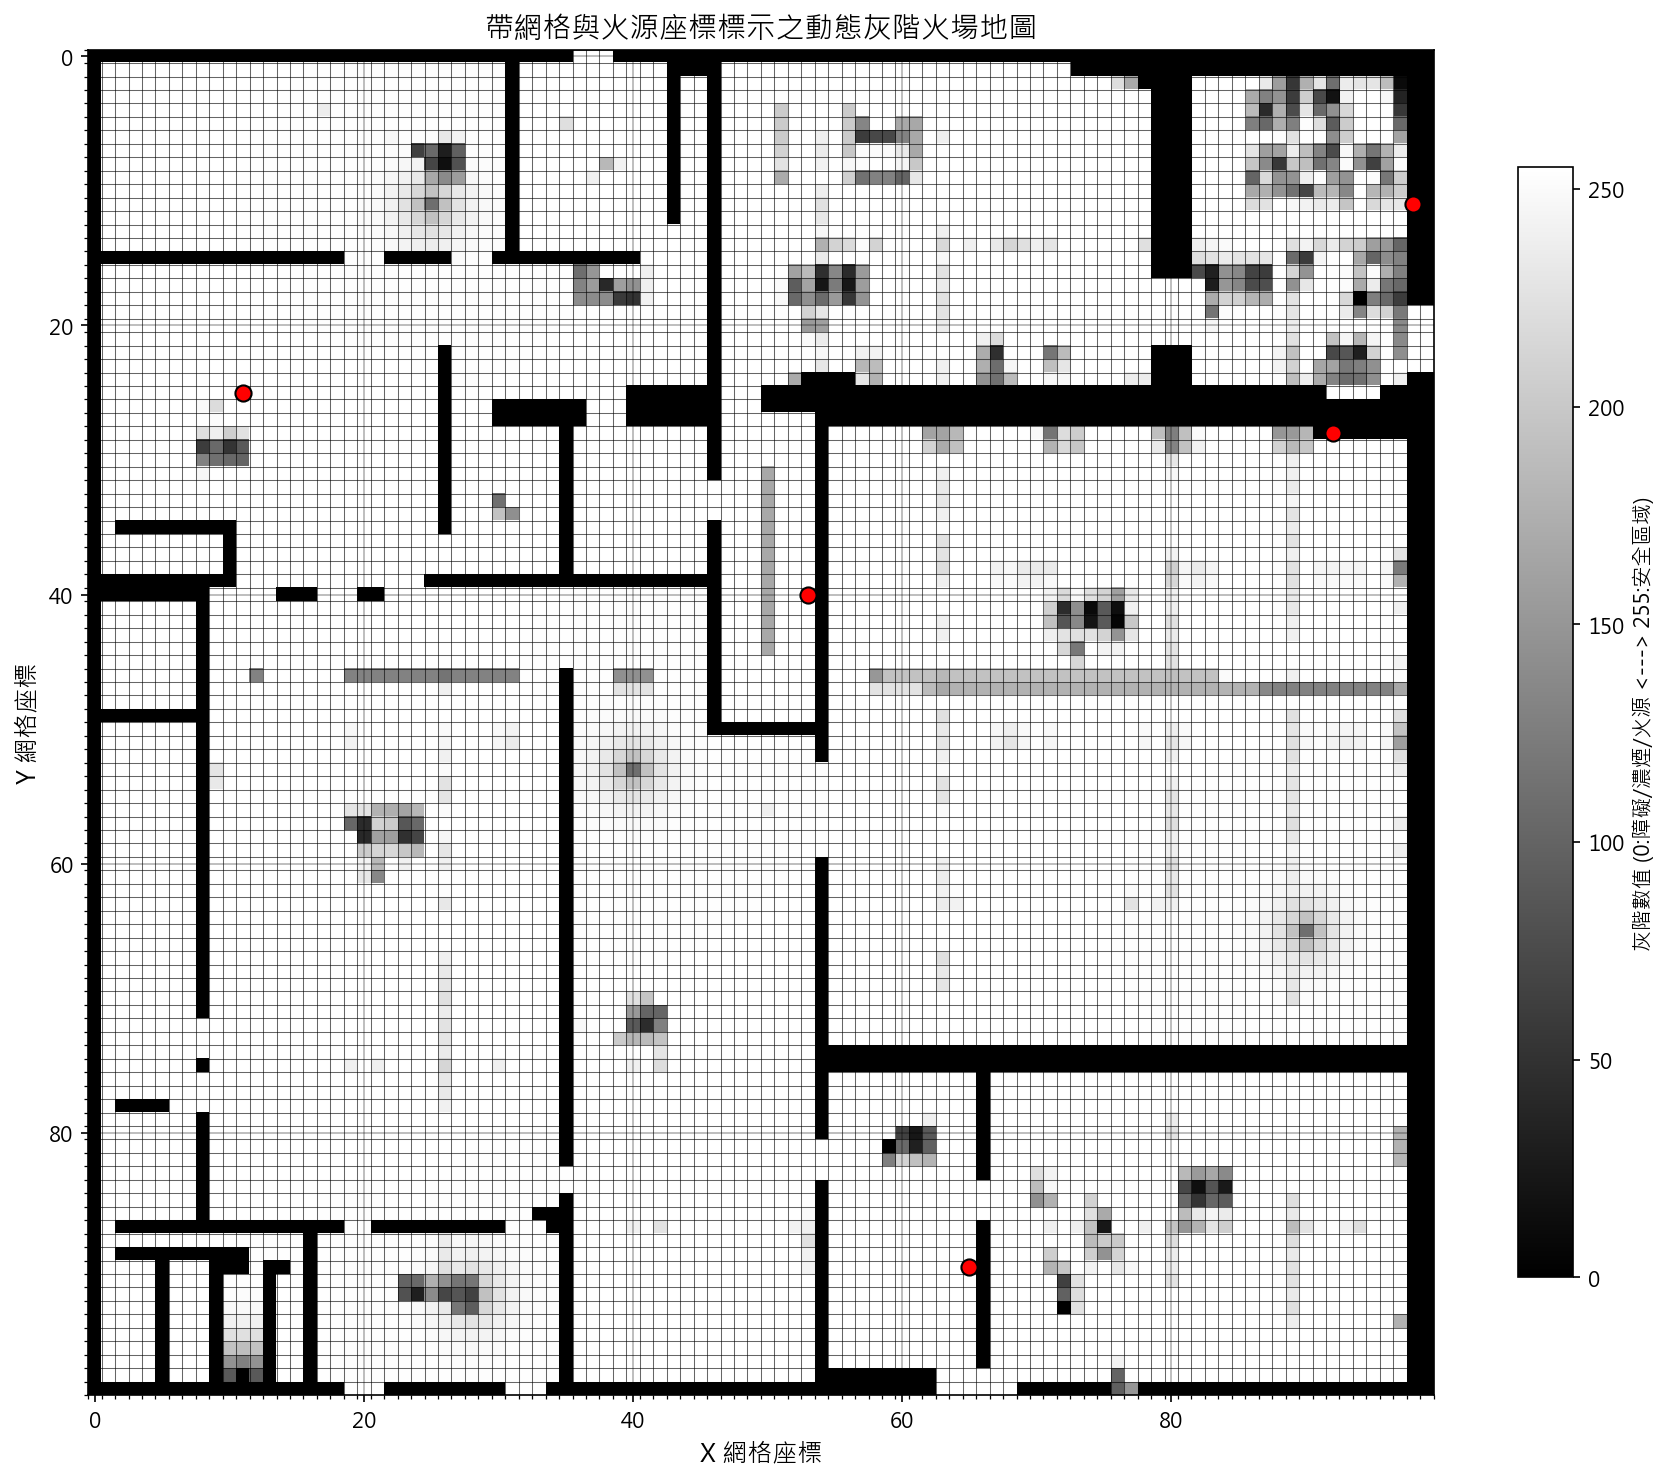

In [23]:
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'SimHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False
# 1. 載入劃記後的網格檔
grid_map = np.load("updated_walkable_grid.npy")

# 2. 模擬火源與煙霧擴散 (這裡呼叫你既有的函式)
# fire_matrix 為火源強度矩陣，fire_pts 為火源座標清單 [(x1, y1), (x2, y2), ...]
fire_matrix, fire_pts = generate_poisson_fire_sources(grid_map)
smoke_matrix = simulate_smoke_diffusion(grid_map, fire_pts, steps=60)

# 3. 計算灰階危害地圖 (論文公式 3.14/3.15)
hazard_gray_map = normalize_and_invert_gray_map(smoke_matrix)
final_map = np.minimum(grid_map, hazard_gray_map)

# ---------------------------------------------------------
# 4. 繪製帶有網格線與火源座標標示的地圖
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 10), dpi=150)

# 顯示灰階地圖 (0:牆/濃煙, 255:安全可通行)
cax = ax.imshow(final_map, cmap="gray", vmin=0, vmax=255, origin="upper")

# A. 加入網格線 (Gridlines)
# 依照你的網格解析度設定刻度間距 (例如每 1 個單位或每 5 個單位一行 grid)
height, width = final_map.shape
ax.set_xticks(np.arange(-0.5, width, 1), minor=True)
ax.set_yticks(np.arange(-0.5, height, 1), minor=True)

# 設定網格線樣式 (紅色虛線或半透明白線，避免遮擋視線)
ax.grid(which="minor", color="black", linestyle="-", linewidth=0.5, alpha=0.6)
ax.grid(which="major", color="black", linestyle="-", linewidth=0.8, alpha=0.3)

# B. 標示火源座標 (Fire Source Coordinates)
for idx, (fy, fx) in enumerate(fire_pts):
    # 在火源位置標示紅點
    ax.scatter(fx, fy, c="red", s=60, marker="o", edgecolors="black", zorder=5)
print(fire_pts)
# C. 設定座標軸與標題
ax.set_xlabel("X 網格座標", fontsize=12)
ax.set_ylabel("Y 網格座標", fontsize=12)
ax.set_title("帶網格與火源座標標示之動態灰階火場地圖", fontsize=14)

# 加入 Colorbar 說明灰階危害度
cbar = fig.colorbar(cax, ax=ax, shrink=0.8)
cbar.set_label("灰階數值 (0:障礙/濃煙/火源 <---> 255:安全區域)", fontsize=10)

plt.tight_layout()
plt.show()